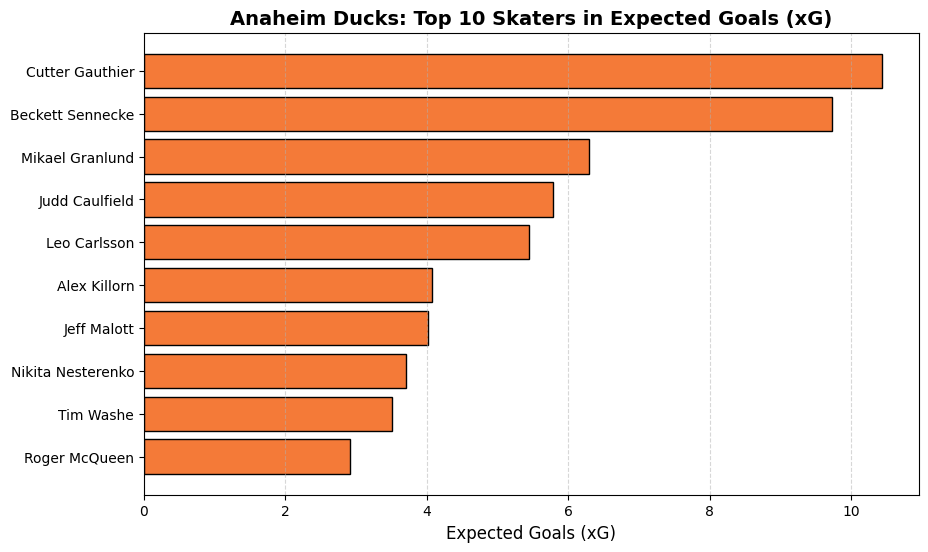

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("skaters.csv")
ducks_all = df[(df["situation"] == "all") & (df["team"] == "ANA")].copy()

#grab top 10 ducks by xGoals & sort ascending

top10_xg = ducks_all.sort_values(by="I_F_xGoals", ascending=False).head(10)
top10_xg = top10_xg.sort_values(by="I_F_xGoals", ascending=True)

plt.figure(figsize=(10, 6))

#draw horiz bars using ANA orange

plt.barh(top10_xg["name"], top10_xg["I_F_xGoals"], color="#F47A38", edgecolor="black")

plt.title("Anaheim Ducks: Top 10 Skaters in Expected Goals (xG)", fontsize=14, fontweight="bold")
plt.xlabel("Expected Goals (xG)", fontsize=12)

#adds suble verticle lines
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()


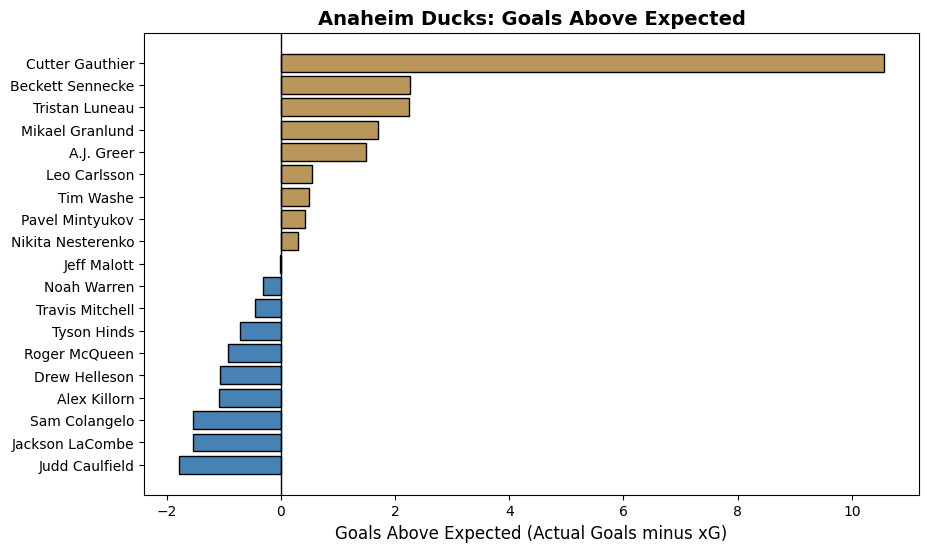

In [16]:
ducks_all["goals_above_expected"] = round(ducks_all["I_F_goals"] - ducks_all["I_F_xGoals"], 2)
regulars = ducks_all[ducks_all["games_played"] >=10].sort_values(by="goals_above_expected", ascending=True)
regulars = regulars.sort_values(by="goals_above_expected", ascending=True)

bar_colors = ["#B9975B" if val >= 0 else "steelblue" for val in regulars["goals_above_expected"]]

plt.figure(figsize=(10, 6))
plt.barh(regulars["name"], regulars["goals_above_expected"], color=bar_colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=1)

plt.title("Anaheim Ducks: Goals Above Expected", fontsize=14, fontweight="bold")
plt.xlabel("Goals Above Expected (Actual Goals minus xG)", fontsize=12)

plt.show()